# Multi-Branch Version 3 — Open-Source Time-Series Stack (`tsai` + `tsaug` + `tsfel`/`tsfresh` + `NOOP`)

This notebook modernises the CMI BFRB detection pipeline with open-source libraries while retaining custom competition logic and `cr7_kimmitch` (NOOP) sensor analytics:
- **Data Augmentation (`tsaug`)**: Time-warping, cropping, multiplicative drift, jitter, relative noise, time-shifting, temporal masking, channel drop, and modality dropout (`thm`/`tof`).
- **Feature Extraction (`tsfel` / `tsfresh` + retained `NOOP` + `cr7_kimmitch`)**: Sample-rate adaptive extraction across IMU (`100 Hz`) and Thermopile/ToF (`20 Hz`), retaining all legacy NOOP features plus `cr7_kimmitch` descriptors (`posture_var`, `motion_cv`, `jerk_floor`, `acc_gyro_coupling`, `dog_var`, `baevsky_si`, `acf_kimmitch`, `peakedness`, and `thm`/`tof` power-branch drift/spread/CV).
- **Network Architecture (`tsai`)**: Multimodal branches for IMU, Thermopile, and 5×8×8 spatial ToF grids using the simplest `'Conv1d'` backbone (or `tsai` backbones) with a compact range of architecture sizes.
- **Competition Scorer & 50% Hidden-Test Simulation**: Exact `(binary_f1 + gesture_f1) / 2` metric evaluated on both the normal holdout set and the simulated hidden test set with `thm_*` and `tof_*` nullified for 50% of sequences.
- **Separate Search Spaces**: Edit `BEST_PARAMS`, `GRID_PARAM_SPACE`, `BAYESIAN_PARAM_SPACE`, or `EVOLUTIONARY_PARAM_SPACE` in their own dedicated cells under `# Params` with zero `.update()` calls.


In [1]:
import os
import sys
import json
import warnings
import importlib
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import torch
try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None

warnings.filterwarnings('ignore')

# Local path routing
current_dir = os.getcwd()
workspace_root = current_dir
if os.path.basename(current_dir) == 'notebooks':
    workspace_root = os.path.dirname(current_dir)

src_path = os.path.join(workspace_root, 'src')
sys.path.insert(0, workspace_root)
sys.path.insert(0, src_path)

# Robust Kaggle path routing (handles nested folders and symlinks from zip uploads)
if os.path.exists('/kaggle/input'):
    for root, dirs, files in os.walk('/kaggle/input', followlinks=True):
        if 'utils_v3.py' in files:
            if root not in sys.path:
                sys.path.insert(0, root)

sys.path.insert(0, src_path)

from sklearn.model_selection import GridSearchCV, GroupKFold, GroupShuffleSplit
from sklearn.pipeline import Pipeline

try:
    import skopt
    from skopt.space import Categorical, Integer, Real
    SKOPT_AVAILABLE = True
except ImportError:
    Categorical = Integer = Real = None
    SKOPT_AVAILABLE = False

import utils_v3
importlib.reload(utils_v3)
from utils_v3 import (
    MultiModalSequenceExtractor,
    NoopOptions,
    TSAugmentor,
    MultiBranchTSAIClassifier,
    ECat,
    EInt,
    EFloat,
    GASearchCV,
    HierarchicalGASearchCV,
    HierarchicalBayesSearchCV,
    build_quick_results_df,
    evaluate_holdout,
    prepare_bayesian_space,
    prepare_evolutionary_space,
    compute_permutation_importance,
    candidate_score,
    refit_valid_candidate,
    deduplicate_param_grid,
    run_validation_searches,
    find_data_root,
    library_status,
    make_synthetic_cmi_df,
)

print('Imports loaded successfully')
print('Library availability:', library_status())
print('CUDA available:', torch.cuda.is_available(), '| Device count:', torch.cuda.device_count())
warnings.filterwarnings('always', message='Candidate skipped:', category=RuntimeWarning)


Imports loaded successfully
Library availability: {'torch': True, 'tsai': False, 'tsaug': False, 'tsfel': True, 'tsfresh': True, 'scikit-optimize': True}
CUDA available: True | Device count: 2


# Setup

In [2]:
experiment_name = 'multibranch_v3_bfrb'

# Supported targets: 'bfrb', 'gesture_action', 'orientation', 'gesture', 'gesture_position'
TARGET_COL = 'bfrb'

# Use sample.csv for a quick smoke test; set False for full train.csv
use_sample_data = False
sample_file = 'sample.csv'

search_mode = 'bayes'  # Choose 'best params', 'bayes', 'evo', or 'grid'
random_state = 42
n_splits = 1           # 1 -> GroupShuffleSplit; >=2 -> GroupKFold

train_size = 0.8
n_iter = 20
verbose = 3
epoch_verbosity = 0
error_score = -1.0     # finite penalty; valid F1 scores are >= 0
n_jobs = 1

# Evolutionary controls: initial population plus configured generations
population_size = 12
generations = 3
tournament_size = 3
elitism = True
crossover_probability = 0.7
mutation_probability = 0.15

INVALID_CANDIDATE_POLICY = 'penalize'  # 'raise' for debugging

orientation_filter_list = []
gesture_position_filter_list = []
gesture_filter_list = []
target_only_bool = False

# Kaggle hidden-test simulation: nullify Thermopile & ToF for 50% of holdout sequences
simulate_hidden_test = False
hidden_test_null_fraction = 0.50

search_mode = str(search_mode).strip().lower()
if search_mode not in ('best params', 'evo', 'bayes', 'grid'):
    raise ValueError("search_mode must be 'best params', 'evo', 'bayes', or 'grid'")

results_dir = Path(workspace_root) / f'results_{experiment_name}_{TARGET_COL}_{search_mode}'
timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')

if n_splits <= 1:
    cv_object = GroupShuffleSplit(
        n_splits=1,
        test_size=(1.0 - train_size),
        random_state=random_state,
    )
else:
    cv_object = GroupKFold(n_splits=n_splits)

VALIDATION_PARAM_SPACE = {
    'validation_mode': ['sequence'],
    'group_column': ['subject'],
}


# Misc 

In [3]:
# Clean baseline reference configuration (augmentations off, minimal regularization,
# all dropouts 0.0, simplest Conv1d architecture, and cr7_kimmitch NOOP descriptors).
BEST_PARAMS = {
    # --- AUGMENTOR (tsaug) ---
    'estimator__augmentor__prob': 0.0,
    'estimator__augmentor__per_aug_prob': 0.0,
    'estimator__augmentor__augmentations': None,
    'estimator__augmentor__n_copies': 1,
    'estimator__augmentor__jitter_sigma': 0.0,
    'estimator__augmentor__noise_std': 0.0,
    'estimator__augmentor__scaling_sigma': 0.0,
    'estimator__augmentor__warp_sigma': 0.0,
    'estimator__augmentor__warp_num_knots': 4,
    'estimator__augmentor__time_warp_max_speed_ratio': 1.0,
    'estimator__augmentor__time_warp_n_speed_change': 3,
    'estimator__augmentor__time_shift_frac': 0.0,
    'estimator__augmentor__crop_frac_range': (1.0, 1.0),
    'estimator__augmentor__temporal_num_masks': 0,
    'estimator__augmentor__temporal_mask_frac': 0.0,
    'estimator__augmentor__temporal_mask_fill': 'ffill',
    'estimator__augmentor__channel_drop_prob': 0.0,
    'estimator__augmentor__sensor_drop_prob': 0.0,
    'estimator__augmentor__sensor_drop_joint_prob': 0.0,
    'estimator__augmentor__random_state': 42,

    # --- EXTRACTOR: Rates & Windowing ---
    'estimator__extractor__sequence_col': 'sequence_id',
    'estimator__extractor__counter_col': 'sequence_counter',
    'estimator__extractor__row_sampling_rate': 100.0,
    'estimator__extractor__align_mode': 'time',
    'estimator__extractor__resample_method': 'poly',
    'estimator__extractor__imu_native_sampling_rate': 100.0,
    'estimator__extractor__rot_native_sampling_rate': 100.0,
    'estimator__extractor__thm_native_sampling_rate': 20.0,
    'estimator__extractor__tof_native_sampling_rate': 20.0,
    'estimator__extractor__imu_target_sampling_rate': None,
    'estimator__extractor__thm_target_sampling_rate': None,
    'estimator__extractor__tof_target_sampling_rate': None,
    'estimator__extractor__window_seconds': 2.5,
    'estimator__extractor__stride_ratio': 0.75,
    'estimator__extractor__final_window_mode': 'overlap',
    'estimator__extractor__max_windows_per_sequence': 200,
    'estimator__extractor__window_cap_policy': 'uniform',

    # --- EXTRACTOR: Sensor Representations & Open-Source Static Features ---
    'estimator__extractor__acc_modes': 'raw|linear',
    'estimator__extractor__use_acc_magnitude': True,
    'estimator__extractor__use_linear_acc_magnitude': True,
    'estimator__extractor__linear_acc_mode': 'auto',
    'estimator__extractor__highpass_hz': 0.3,
    'estimator__extractor__use_highpass_fallback': True,
    'estimator__extractor__rotation_modes': 'quaternion|angular_velocity',
    'estimator__extractor__fix_quaternion_sign': True,
    'estimator__extractor__thm_modes': 'centered_diff',
    'estimator__extractor__tof_modes': 'pooled_stats|sensor_stats',
    'estimator__extractor__tof_fill_mode': 'far_500',
    'estimator__extractor__static_backend': 'tsfel',
    'estimator__extractor__static_channels': 'acc_mag|lin_mag|ang_speed|thm_mean|tof_mean',
    'estimator__extractor__tsfel_domains': 'statistical|temporal|spectral',
    'estimator__extractor__tsfel_features': None,
    'estimator__extractor__tsfresh_profile': 'minimal',
    'estimator__extractor__tsfresh_fft_bands': ((0.5, 2.0), (2.0, 4.0), (4.0, 8.0)),
    'estimator__extractor__static_clip': 10.0,

    # --- EXTRACTOR: NOOP + cr7_kimmitch Features ---
    'estimator__extractor__noop__motion_stats': 'kimmitch',
    'estimator__extractor__noop__periodicity': 'acf_kimmitch',
    'estimator__extractor__noop__spectral_stats': 'all',
    'estimator__extractor__noop__quality': 'features',
    'estimator__extractor__noop__signal': 'raw',
    'estimator__extractor__noop__band': (0.5, 8.0),
    'estimator__extractor__noop__bands': ((0.5, 2.0), (2.0, 4.0), (4.0, 8.0)),
    'estimator__extractor__noop__min_cycles': 2.0,
    'estimator__extractor__noop__min_samples': 16,
    'estimator__extractor__noop__max_gap_samples': 2,
    'estimator__extractor__noop__acf_harmonic_tolerance': 0.1,
    'estimator__extractor__noop__spectral_neighbourhood_hz': 0.5,
    'estimator__extractor__noop__detrend': 'constant',
    'estimator__extractor__noop__cadence_band': (1.2, 3.5),
    'estimator__extractor__noop__min_cadence_strength': 0.2,
    'estimator__extractor__noop__power_branches': 'imu|thm|tof',
    'estimator__extractor__noop__nyquist_policy': 'clip',

    # --- MODEL: Simplest Architecture ('Conv1d') & Sizes ---
    'estimator__arch': 'Conv1d',
    'estimator__imu_arch': None,
    'estimator__thm_arch': None,
    'estimator__tof_arch': None,
    'estimator__branch_filters': 64,
    'estimator__branch_depth': 2,
    'estimator__branch_kernel_size': 7,
    'estimator__branch_units': 64,
    'estimator__attention_heads': 4,
    'estimator__pooling_mode': 'attention',
    'estimator__attention_units': 64,
    'estimator__tof_spatial_mode': 'auto',
    'estimator__tof_spatial_filters': 16,
    'estimator__tof_spatial_kernel': 3,
    'estimator__static_units': 64,
    'estimator__static_layers': 1,
    'estimator__fusion_type': 'attention',
    'estimator__fusion_units': 64,
    'estimator__dense_units': 64,
    'estimator__dense_layers': 1,
    'estimator__activation': 'gelu',
    'estimator__use_batchnorm': True,

    # --- MODEL: Regularization & Dropouts (all 0.0 in baseline) ---
    'estimator__dropout': 0.0,
    'estimator__branch_dropout': 0.0,
    'estimator__conv_dropout': 0.0,
    'estimator__static_dropout': 0.0,
    'estimator__fusion_dropout': 0.0,
    'estimator__weight_decay': 0.0,
    'estimator__label_smoothing': 0.0,

    # --- MODEL: Optimizer, Loss & Training Loop ---
    'estimator__primary_target': TARGET_COL,
    'estimator__optimizer_name': 'adamw',
    'estimator__learning_rate': 1e-3,
    'estimator__momentum': 0.9,
    'estimator__gradient_clip_norm': 1.0,
    'estimator__loss_name': 'focal',
    'estimator__focal_gamma': 2.0,
    'estimator__class_weight_mode': 'balanced',
    'estimator__use_lr_scheduler': True,
    'estimator__lr_scheduler_type': 'cosine',
    'estimator__lr_factor': 0.5,
    'estimator__lr_patience': 5,
    'estimator__min_lr': 1e-6,
    'estimator__cosine_t_max': 25,
    'estimator__warmup_epochs': 2,
    'estimator__epochs': 25,
    'estimator__batch_size': 64,
    'estimator__validation_split': 0.15,
    'estimator__validation_group_column': None,
    'estimator__early_stopping_patience': 8,
    'estimator__restore_best_weights': True,
    'estimator__sequence_aggregation': 'mean_proba',
    'estimator__invalid_candidate_policy': INVALID_CANDIDATE_POLICY,
    'estimator__invalid_candidate_score': error_score,
    'estimator__device': None,
    'estimator__verbose': epoch_verbosity,
    'estimator__random_state': random_state,
}


# Prep

In [4]:
# Load and prepare training data without retaining a second sensor frame.
data_root = find_data_root()
sample_path = data_root / sample_file
if not sample_path.exists():
    local_sample = Path(workspace_root) / 'data' / sample_file
    if local_sample.exists():
        sample_path = local_sample

if use_sample_data and sample_path.exists():
    data_path = sample_path
elif (data_root / 'train.csv').exists():
    data_path = data_root / 'train.csv'
elif sample_path.exists() and not Path('/kaggle/input').is_dir():
    data_path = sample_path
else:
    data_path = data_root / 'train.csv'

if data_path.exists():
    sensor_columns = [
        column for column in pd.read_csv(data_path, nrows=0).columns
        if column.startswith(('acc_', 'rot_', 'tof_', 'thm_'))
    ]
    train_df = pd.read_csv(data_path, dtype={column: np.float32 for column in sensor_columns})
    print(f'Using {data_path}: {train_df["sequence_id"].nunique()} sequences')
elif Path('/kaggle/input').is_dir():
    raise FileNotFoundError(
        f'Could not find train.csv (checked {data_root}). '
        'Ensure the cmi-detect-behavior-with-sensor-data competition dataset is attached to the Kaggle notebook.'
    )
else:
    train_df = make_synthetic_cmi_df(n_subjects=8, sequences_per_subject=4, n_timesteps=80, random_state=random_state)
    sensor_columns = [c for c in train_df.columns if c.startswith(('acc_', 'rot_', 'tof_', 'thm_'))]
    print(f'Using synthetic CMI dataset fallback: {train_df["sequence_id"].nunique()} sequences')

train_df['gesture'] = train_df['gesture'].fillna('non_bfrb').astype(str)
train_df['orientation'] = train_df.get('orientation', pd.Series('Seated Straight', index=train_df.index)).fillna('Unknown').astype(str)
if 'sequence_type' in train_df.columns:
    train_df['is_target'] = train_df['sequence_type'].eq('Target').astype(np.uint8)
else:
    train_df['is_target'] = train_df.get('is_target', pd.Series(1, index=train_df.index)).astype(np.uint8)
train_df['bfrb'] = train_df['gesture'].where(train_df['is_target'].eq(1), 'non_bfrb')

gesture_parts = {gesture: gesture.split(' - ') for gesture in train_df['gesture'].unique()}
train_df['gesture_position'] = train_df['gesture'].map({gesture: parts[0] for gesture, parts in gesture_parts.items()})
train_df['gesture_action'] = train_df['gesture'].map({gesture: parts[-1] for gesture, parts in gesture_parts.items()})

if TARGET_COL not in {'bfrb', 'gesture_action', 'orientation', 'gesture', 'gesture_position'}:
    raise ValueError('Unsupported TARGET_COL.')

keep_rows = pd.Series(True, index=train_df.index)
if orientation_filter_list:
    keep_rows &= train_df['orientation'].isin(orientation_filter_list)
if gesture_position_filter_list:
    keep_rows &= train_df['gesture_position'].isin(gesture_position_filter_list)
if gesture_filter_list:
    keep_rows &= train_df['gesture'].isin(gesture_filter_list)
if target_only_bool:
    keep_rows &= train_df['is_target'].eq(1)
if not keep_rows.all():
    train_df = train_df.loc[keep_rows].copy()
del keep_rows, gesture_parts

quaternion_cols = ['rot_w', 'rot_x', 'rot_y', 'rot_z']
quaternions = train_df[quaternion_cols].to_numpy(dtype=np.float64)
valid_quaternion = np.isfinite(quaternions).all(axis=1) & (np.linalg.norm(quaternions, axis=1) > 0)
orientation_available = pd.Series(valid_quaternion, index=train_df.index).groupby(train_df['sequence_id']).any()
excluded_orientation_ids = orientation_available.index[~orientation_available].tolist()
if excluded_orientation_ids:
    print(f'Excluding {len(excluded_orientation_ids)} sequences with no valid orientation before splitting.')
    train_df = train_df[~train_df['sequence_id'].isin(excluded_orientation_ids)].copy()

del quaternions, valid_quaternion, orientation_available

train_df[TARGET_COL] = train_df[TARGET_COL].fillna('non_bfrb').astype(str)
print(f'Target: {TARGET_COL}; sequences after filters: {train_df["sequence_id"].nunique()}')


Using Kaggle data folder: /kaggle/input/competitions/cmi-detect-behavior-with-sensor-data
Using /kaggle/input/competitions/cmi-detect-behavior-with-sensor-data/train.csv: 8151 sequences
Excluding 50 sequences with no valid orientation before splitting.
Target: bfrb; sequences after filters: 8101


In [5]:
# Keep complete sequences available; each selected validation protocol splits them
# before extraction and scaling. Sequence splitting remains the default.
experiment_df = train_df
del train_df
print('Available sequences:', experiment_df['sequence_id'].nunique())


Available sequences: 8101


In [6]:
extractor = MultiModalSequenceExtractor(
    noop=NoopOptions(),
    imu_native_sampling_rate=100.0,
    rot_native_sampling_rate=100.0,
    thm_native_sampling_rate=20.0,
    tof_native_sampling_rate=20.0,
)

clf = MultiBranchTSAIClassifier(
    extractor=extractor,
    augmentor=TSAugmentor(prob=0.0, per_aug_prob=0.0, random_state=random_state),
    primary_target=TARGET_COL,
    arch='Conv1d',
    dropout=0.0,
    branch_dropout=0.0,
    conv_dropout=0.0,
    static_dropout=0.0,
    fusion_dropout=0.0,
    weight_decay=0.0,
    label_smoothing=0.0,
    invalid_candidate_policy=INVALID_CANDIDATE_POLICY,
    candidate_failure_log=str(results_dir / f'{timestamp}_candidate_failures.jsonl'),
    verbose=epoch_verbosity,
    random_state=random_state,
)
pipeline = Pipeline([('estimator', clf)])


# Params

Search spaces are organised into three separate, self-contained cells (`GRID_PARAM_SPACE`, `BAYESIAN_PARAM_SPACE`, and `EVOLUTIONARY_PARAM_SPACE`) with zero `.update()` calls:

1. **Clean Starting Combination for Bayesian Search**: Iteration 0 deterministically starts with augmentations switched off (`prob=0.0`, `per_aug_prob=0.0`), minimal regularization (`weight_decay=0.0`, `label_smoothing=0.0`), and all dropouts set to `0.0` (`dropout=0.0`, `branch_dropout=0.0`, `conv_dropout=0.0`, `static_dropout=0.0`, `fusion_dropout=0.0`).
2. **Feature Extractions (3 Options Each)**: Every feature-extraction mode (`acc_modes`, `rotation_modes`, `thm_modes`, `tof_modes`, `static_backend`, `static_channels`, `tsfel_domains`, and `noop__motion_stats`, `noop__periodicity`, `noop__spectral_stats`, `noop__power_branches`, `noop__signal`, `noop__quality`) exposes 3 options.
3. **One Simplest Architecture + Small Size Range**: Fixes `estimator__arch` to `'Conv1d'` and explores a compact range of sizes (`branch_filters`: `[64, 96, 128]`, `branch_depth`: `[2, 3]`, `branch_units`: `[64, 96, 128]`, `fusion_units`: `[64, 96, 128]`, `dense_units`: `[64, 96, 128]`).
4. **Minimal Regularization Exploration (2 Options)**: Dropouts explore `[0.0, 0.1]`, weight decay explores `[0.0, 1e-5]`, and label smoothing explores `[0.0, 0.05]`.


## Grid

In [7]:
# GRID SEARCH ONLY
GRID_PARAM_SPACE = {
    # ----------------------------------------------------------
    # AUGMENTOR (tsaug — starts with 0.0 / off)
    # ----------------------------------------------------------
    'estimator__augmentor__prob': [0.0, 0.25],
    'estimator__augmentor__per_aug_prob': [0.0, 0.5],
    'estimator__augmentor__augmentations': [None],
    'estimator__augmentor__n_copies': [1],
    'estimator__augmentor__jitter_sigma': [0.0, 0.02],
    'estimator__augmentor__noise_std': [0.0, 0.05],
    'estimator__augmentor__scaling_sigma': [0.0, 0.1],
    'estimator__augmentor__warp_sigma': [0.0, 0.1],
    'estimator__augmentor__warp_num_knots': [4],
    'estimator__augmentor__time_warp_max_speed_ratio': [1.0, 1.15],
    'estimator__augmentor__time_warp_n_speed_change': [3],
    'estimator__augmentor__time_shift_frac': [0.0, 0.05],
    'estimator__augmentor__crop_frac_range': [(1.0, 1.0), (0.85, 1.0)],
    'estimator__augmentor__temporal_num_masks': [0, 2],
    'estimator__augmentor__temporal_mask_frac': [0.0, 0.1],
    'estimator__augmentor__temporal_mask_fill': ['ffill'],
    'estimator__augmentor__channel_drop_prob': [0.0, 0.1],
    'estimator__augmentor__sensor_drop_prob': [0.0, 0.15],
    'estimator__augmentor__sensor_drop_joint_prob': [0.0, 0.15],
    'estimator__augmentor__random_state': [random_state],

    # ----------------------------------------------------------
    # EXTRACTOR — Sampling Rates & Windowing
    # ----------------------------------------------------------
    'estimator__extractor__sequence_col': ['sequence_id'],
    'estimator__extractor__counter_col': ['sequence_counter'],
    'estimator__extractor__row_sampling_rate': [100.0],
    'estimator__extractor__align_mode': ['time'],
    'estimator__extractor__resample_method': ['poly'],
    'estimator__extractor__imu_native_sampling_rate': [100.0],
    'estimator__extractor__rot_native_sampling_rate': [100.0],
    'estimator__extractor__thm_native_sampling_rate': [20.0],
    'estimator__extractor__tof_native_sampling_rate': [20.0],
    'estimator__extractor__imu_target_sampling_rate': [None],
    'estimator__extractor__thm_target_sampling_rate': [None],
    'estimator__extractor__tof_target_sampling_rate': [None],
    'estimator__extractor__window_seconds': [2.5],
    'estimator__extractor__stride_ratio': [0.75],
    'estimator__extractor__final_window_mode': ['overlap'],
    'estimator__extractor__max_windows_per_sequence': [200],
    'estimator__extractor__window_cap_policy': ['uniform'],

    # ----------------------------------------------------------
    # EXTRACTOR — Feature Extractions (3 options each)
    # ----------------------------------------------------------
    'estimator__extractor__acc_modes': ['raw', 'raw|linear', 'raw|linear|jerk'],
    'estimator__extractor__use_acc_magnitude': [True],
    'estimator__extractor__use_linear_acc_magnitude': [True],
    'estimator__extractor__linear_acc_mode': ['auto', 'quaternion', 'highpass'],
    'estimator__extractor__highpass_hz': [0.3],
    'estimator__extractor__use_highpass_fallback': [True],
    'estimator__extractor__rotation_modes': ['quaternion', 'angular_velocity', 'quaternion|angular_velocity'],
    'estimator__extractor__fix_quaternion_sign': [True],
    'estimator__extractor__thm_modes': ['raw', 'centered_diff', 'raw|centered_diff|pooled_stats'],
    'estimator__extractor__tof_modes': ['pooled_stats', 'pooled_stats|sensor_stats', 'raw|pooled_stats|sensor_stats'],
    'estimator__extractor__tof_fill_mode': ['far_500'],
    'estimator__extractor__static_backend': ['none', 'tsfel', 'tsfresh'],
    'estimator__extractor__static_channels': [
        'acc_mag|ang_speed',
        'acc_mag|lin_mag|ang_speed',
        'acc_mag|lin_mag|ang_speed|thm_mean|tof_mean',
    ],
    'estimator__extractor__tsfel_domains': [
        'statistical',
        'statistical|temporal',
        'statistical|temporal|spectral',
    ],
    'estimator__extractor__tsfel_features': [None],
    'estimator__extractor__tsfresh_profile': ['minimal'],
    'estimator__extractor__tsfresh_fft_bands': [((0.5, 2.0), (2.0, 4.0), (4.0, 8.0))],
    'estimator__extractor__static_clip': [10.0],

    # ----------------------------------------------------------
    # EXTRACTOR — NOOP + cr7_kimmitch (3 options each)
    # ----------------------------------------------------------
    'estimator__extractor__noop__motion_stats': ['basic', 'kimmitch', 'full'],
    'estimator__extractor__noop__periodicity': ['acf_cadence', 'acf_kimmitch', 'acf_harmonic_checked'],
    'estimator__extractor__noop__spectral_stats': [
        'peak_fraction|entropy',
        'peak_fraction|band_fractions|peakedness',
        'all',
    ],
    'estimator__extractor__noop__quality': [None, 'report', 'features'],
    'estimator__extractor__noop__signal': ['raw', 'linear', 'angular_speed'],
    'estimator__extractor__noop__band': [(0.5, 8.0)],
    'estimator__extractor__noop__bands': [((0.5, 2.0), (2.0, 4.0), (4.0, 8.0))],
    'estimator__extractor__noop__min_cycles': [2.0],
    'estimator__extractor__noop__min_samples': [16],
    'estimator__extractor__noop__max_gap_samples': [2],
    'estimator__extractor__noop__acf_harmonic_tolerance': [0.1],
    'estimator__extractor__noop__spectral_neighbourhood_hz': [0.5],
    'estimator__extractor__noop__detrend': ['constant'],
    'estimator__extractor__noop__cadence_band': [(1.2, 3.5)],
    'estimator__extractor__noop__min_cadence_strength': [0.2],
    'estimator__extractor__noop__power_branches': ['imu', 'imu|thm', 'imu|thm|tof'],
    'estimator__extractor__noop__nyquist_policy': ['clip'],

    # ----------------------------------------------------------
    # MODEL — One Simplest Architecture ('Conv1d') & Small Size Range
    # ----------------------------------------------------------
    'estimator__arch': ['Conv1d'],
    'estimator__imu_arch': [None],
    'estimator__thm_arch': [None],
    'estimator__tof_arch': [None],
    'estimator__branch_filters': [64, 96, 128],
    'estimator__branch_depth': [2, 3],
    'estimator__branch_kernel_size': [5, 7],
    'estimator__branch_units': [64, 96, 128],
    'estimator__attention_heads': [4],
    'estimator__pooling_mode': ['attention'],
    'estimator__attention_units': [64],
    'estimator__tof_spatial_mode': ['auto'],
    'estimator__tof_spatial_filters': [8, 16],
    'estimator__tof_spatial_kernel': [3],
    'estimator__static_units': [32, 64],
    'estimator__static_layers': [1, 2],
    'estimator__fusion_type': ['attention'],
    'estimator__fusion_units': [64, 96, 128],
    'estimator__dense_units': [64, 96, 128],
    'estimator__dense_layers': [1, 2],
    'estimator__activation': ['gelu'],
    'estimator__use_batchnorm': [True],

    # ----------------------------------------------------------
    # MODEL — Regularization & Dropouts (2 options, starting at 0.0)
    # ----------------------------------------------------------
    'estimator__dropout': [0.0, 0.1],
    'estimator__branch_dropout': [0.0, 0.1],
    'estimator__conv_dropout': [0.0, 0.1],
    'estimator__static_dropout': [0.0, 0.1],
    'estimator__fusion_dropout': [0.0, 0.1],
    'estimator__weight_decay': [0.0, 1e-5],
    'estimator__label_smoothing': [0.0, 0.05],

    # ----------------------------------------------------------
    # MODEL — Optimizer, Loss & Training Loop
    # ----------------------------------------------------------
    'estimator__primary_target': [TARGET_COL],
    'estimator__optimizer_name': ['adamw'],
    'estimator__learning_rate': [5e-4, 1e-3],
    'estimator__momentum': [0.9],
    'estimator__gradient_clip_norm': [1.0],
    'estimator__loss_name': ['focal'],
    'estimator__focal_gamma': [2.0],
    'estimator__class_weight_mode': ['balanced'],
    'estimator__use_lr_scheduler': [True],
    'estimator__lr_scheduler_type': ['cosine'],
    'estimator__lr_factor': [0.5],
    'estimator__lr_patience': [5],
    'estimator__min_lr': [1e-6],
    'estimator__cosine_t_max': [25],
    'estimator__warmup_epochs': [2],
    'estimator__epochs': [25],
    'estimator__batch_size': [64],
    'estimator__validation_split': [0.15],
    'estimator__validation_group_column': [None],
    'estimator__early_stopping_patience': [8],
    'estimator__restore_best_weights': [True],
    'estimator__sequence_aggregation': ['mean_proba'],
    'estimator__invalid_candidate_policy': [INVALID_CANDIDATE_POLICY],
    'estimator__invalid_candidate_score': [error_score],
    'estimator__device': [None],
    'estimator__verbose': [epoch_verbosity],
    'estimator__random_state': [random_state],
}


## Bayesian

In [8]:
# BAYESIAN SEARCH ONLY
# Starting combination (Iteration 0): augmentations switched off (0.0), minimal regularization
# (weight_decay=0.0, label_smoothing=0.0), and all dropouts set to 0.0.
# Feature extractions have 3 options each; architecture tests 'Conv1d' across a small size range.
BAYESIAN_PARAM_SPACE = dict()
if SKOPT_AVAILABLE:
    # 1. Minimal: Extremely fast, low-memory baseline (prevents crashes)
    tsfel_minimal = {
        "statistical": {
            "Mean": {"use": "yes"},
            "Variance": {"use": "yes"},
            "Maximum": {"use": "yes"},
            "Minimum": {"use": "yes"}
        }
    }

    # 2. Kinematic: Hand-picked specifically for IMU gesture/motion analysis
    tsfel_kinematic = {
        "statistical": {
            "Mean": {"use": "yes"},
            "Variance": {"use": "yes"},
            "Root mean square": {"use": "yes"}
        },
        "temporal": {
            "Peak to peak distance": {"use": "yes"},
            "Zero crossing rate": {"use": "yes"},
            "Signal distance": {"use": "yes"}, 
            "Slope": {"use": "yes"}
        }
    }

    # 3. Complexity: Focuses on unpredictability (often predictive of BFRB tremors)
    tsfel_entropy = {
        "statistical": {
            "Entropy": {"use": "yes"}
        },
        "temporal": {
            "Complexity": {"use": "yes"}
        },
        "spectral": {
            "Spectral entropy": {"use": "yes"},
            "Fundamental frequency": {"use": "yes"}
        }
    }

    BAYESIAN_PARAM_SPACE = {
        # ----------------------------------------------------------
        # AUGMENTOR (tsaug — 0.0 first so Bayes starts with augmentations off)
        # ----------------------------------------------------------
        'estimator__augmentor__prob': Categorical([0.0]),
        'estimator__augmentor__per_aug_prob': Categorical([0.0]),
        'estimator__augmentor__augmentations': Categorical([None]),
        'estimator__augmentor__n_copies': Categorical([1]),
        'estimator__augmentor__jitter_sigma': Categorical([0.0]),
        'estimator__augmentor__noise_std': Categorical([0.0]),
        'estimator__augmentor__scaling_sigma': Categorical([0.0]),
        'estimator__augmentor__warp_sigma': Categorical([0.0]),
        'estimator__augmentor__warp_num_knots': Categorical([4]),
        'estimator__augmentor__time_warp_max_speed_ratio': Categorical([1.0]),
        'estimator__augmentor__time_warp_n_speed_change': Categorical([3]),
        'estimator__augmentor__time_shift_frac': Categorical([0.0]),
        'estimator__augmentor__crop_frac_range': Categorical([
            json.dumps((1.0, 1.0), sort_keys=True),
        #     json.dumps((0.85, 1.0), sort_keys=True),
        ]),
        'estimator__augmentor__temporal_num_masks': Categorical([0]),
        'estimator__augmentor__temporal_mask_frac': Categorical([0.0]),
        'estimator__augmentor__temporal_mask_fill': Categorical(['ffill']),
        'estimator__augmentor__channel_drop_prob': Categorical([0.0]),
        'estimator__augmentor__sensor_drop_prob': Categorical([0.0]),
        'estimator__augmentor__sensor_drop_joint_prob': Categorical([0.0]),
        'estimator__augmentor__random_state': Categorical([random_state]),

        # ----------------------------------------------------------
        # EXTRACTOR — Sampling Rates & Windowing
        # ----------------------------------------------------------
        'estimator__extractor__sequence_col': Categorical(['sequence_id']),
        'estimator__extractor__counter_col': Categorical(['sequence_counter']),
        'estimator__extractor__row_sampling_rate': Categorical([100.0]),
        'estimator__extractor__align_mode': Categorical(['time']),
        'estimator__extractor__resample_method': Categorical(['poly']),
        'estimator__extractor__imu_native_sampling_rate': Categorical([100.0]),
        'estimator__extractor__rot_native_sampling_rate': Categorical([100.0]),
        'estimator__extractor__thm_native_sampling_rate': Categorical([20.0]),
        'estimator__extractor__tof_native_sampling_rate': Categorical([20.0]),
        'estimator__extractor__imu_target_sampling_rate': Categorical([None]),
        'estimator__extractor__thm_target_sampling_rate': Categorical([None]),
        'estimator__extractor__tof_target_sampling_rate': Categorical([None]),
        'estimator__extractor__window_seconds': Categorical([2.5]),
        'estimator__extractor__stride_ratio': Categorical([0.75]),
        'estimator__extractor__final_window_mode': Categorical(['overlap']),
        'estimator__extractor__max_windows_per_sequence': Categorical([200]),
        'estimator__extractor__window_cap_policy': Categorical(['uniform']),

        # ----------------------------------------------------------
        # EXTRACTOR — Feature Extractions (3 options each)
        # ----------------------------------------------------------
        'estimator__extractor__acc_modes': Categorical(['linear|jerk']),
        'estimator__extractor__use_acc_magnitude': Categorical([True]),
        'estimator__extractor__use_linear_acc_magnitude': Categorical([True]),
        'estimator__extractor__linear_acc_mode': Categorical(['auto']),
        'estimator__extractor__highpass_hz': Categorical([0.3]),
        'estimator__extractor__use_highpass_fallback': Categorical([True]),
        'estimator__extractor__rotation_modes': Categorical([None, 'angular_velocity', 'quaternion|angular_velocity']),
        'estimator__extractor__fix_quaternion_sign': Categorical([True]),
        'estimator__extractor__thm_modes': Categorical(['centered_diff']),
        'estimator__extractor__tof_modes': Categorical(['raw', 'raw|pooled_stats|sensor_stats']),
        'estimator__extractor__tof_fill_mode': Categorical(['far_500']),
        'estimator__extractor__static_backend': Categorical(['none']),
        'estimator__extractor__static_channels': Categorical([
            'acc_mag|ang_speed',
            # 'acc_mag|lin_mag|ang_speed',
            # 'acc_mag|lin_mag|ang_speed|thm_mean|tof_mean',
        ]),


        # ----------------------------------------------------------
        # EXTRACTOR — TSFEL & TSFRESH (Expanded Profiles & Bands)
        # ----------------------------------------------------------
        # TSFEL domains: combination of the 3 available domains
        'estimator__extractor__tsfel_domains': Categorical([
            # 'statistical',
            # 'statistical|temporal',
            'statistical|temporal|spectral'
        ]),

        # Update your Bayesian search space dictionary with this:
        'estimator__extractor__tsfel_features': Categorical([
            None,                                         # Calculates ALL features (High risk of crashing)
            # json.dumps(tsfel_minimal, sort_keys=True),    # Safest, fastest subset
            # json.dumps(tsfel_kinematic, sort_keys=True),  # Best for IMU accelerometer/gyro data
            # json.dumps(tsfel_entropy, sort_keys=True)     # Tests if BFRB gestures are uniquely chaotic
        ]),

        # TSFresh profiles: minimal is safest, efficient is standard ML baseline, comprehensive is massive
        'estimator__extractor__tsfresh_profile': Categorical(['minimal']),

        # TSFresh FFT Bands: 
        # 1. Broad / Simple (less memory)
        # 2. Medium (Your original)
        # 3. Highly Granular / Big (Captures specific tremor frequencies)
        'estimator__extractor__tsfresh_fft_bands': Categorical([
                    # 1. Baseline: Your current best (Focuses purely on slow to moderate gestures)
                    json.dumps(((0.5, 1.5), (1.5, 3.0), (3.0, 6.0), (6.0, 10.0)), sort_keys=True),
                    
                    # 2. Mild Extension: Captures slightly faster tremors/shivering
                    json.dumps(((0.5, 2.0), (2.0, 5.0), (5.0, 10.0), (10.0, 15.0)), sort_keys=True),
                    
                    # 3. Moderate Extension: Captures rapid micro-movements safely away from the filter wasteland
                    json.dumps(((0.5, 3.0), (3.0, 8.0), (8.0, 15.0), (15.0, 25.0)), sort_keys=True),
                    
                    # 4. Aggressive Nyquist Limit: Pushes all the way to 50 Hz (Warning: 40-50 Hz will contain filter noise)
                    json.dumps(((0.5, 5.0), (5.0, 12.0), (12.0, 25.0), (25.0, 50.0)), sort_keys=True),
                ]),
        'estimator__extractor__static_clip': Categorical([100.0]),

        # ----------------------------------------------------------
        # EXTRACTOR — NOOP + cr7_kimmitch (Expanded Ranges)
        # ----------------------------------------------------------
        # Motion stats: Basic is lightweight; kimmitch uses custom logic; full extracts everything
        'estimator__extractor__noop__motion_stats': Categorical([None]),

        # Periodicity: Testing standard cadence vs. your custom BFRB logic
        'estimator__extractor__noop__periodicity': Categorical(['acf_kimmitch']),

        # Spectral stats: Granular breakdown to prevent OOM errors while finding the most predictive features
        'estimator__extractor__noop__spectral_stats': Categorical([
            # None,
            'entropy',
            # 'peak_fraction|entropy',
            # 'peak_fraction|band_fractions|peakedness',
            # 'all',
        ]),

        'estimator__extractor__noop__quality': Categorical([None]),
        'estimator__extractor__noop__signal': Categorical(['raw']),

        # Spectral Bands: Narrow vs Wide coverage
        'estimator__extractor__noop__band': Categorical([
            json.dumps((0.5, 4.0), sort_keys=True),
            json.dumps((0.5, 8.0), sort_keys=True),
            json.dumps((1.0, 15.0), sort_keys=True),
            json.dumps((0.5, 50.0), sort_keys=True)
        ]),
        'estimator__extractor__noop__bands': Categorical([
            # 1. Baseline: Best performing (Focuses purely on standard motion)
            json.dumps(((0.5, 4.0), (4.0, 8.0)), sort_keys=True),
            
            # 2. Triple Split: Explores up to 20 Hz
            json.dumps(((0.5, 5.0), (5.0, 10.0), (10.0, 20.0)), sort_keys=True),
            
            # 3. Aggressive: Explores up to 30 Hz
            json.dumps(((0.5, 8.0), (8.0, 15.0), (15.0, 30.0)), sort_keys=True),
            
            # 4. The Absolute Limit: Pushes all the way to 50 Hz
            json.dumps(((0.5, 10.0), (10.0, 25.0), (25.0, 50.0)), sort_keys=True),
        ]),

        # NOOP Numeric Thresholds (Smaller and Bigger bounds)
        'estimator__extractor__noop__min_cycles': Categorical([3.0, 5.0]),
        'estimator__extractor__noop__min_samples': Categorical([6, 8]),
        'estimator__extractor__noop__max_gap_samples': Categorical([1, 2]),
        'estimator__extractor__noop__acf_harmonic_tolerance': Categorical([0.05, 0.1]),
        'estimator__extractor__noop__spectral_neighbourhood_hz': Categorical([0.25, 0.5, 1.0, 5.0]),
        'estimator__extractor__noop__detrend': Categorical(['constant', 'linear']),

        # Cadence bands for periodic movements
        'estimator__extractor__noop__cadence_band': Categorical([
            # 1. Baseline: Best performing (Restricts rhythms to realistic scratching speeds)
            json.dumps((0.8, 2.5), sort_keys=True),
            
            # 2. Fast Gestures: Pushes up to 5 Hz (5 taps per second)
            json.dumps((0.5, 5.0), sort_keys=True),
            
            # 3. Micro-Tremors: Pushes up to 10 Hz (Very fast shivering)
            json.dumps((2.0, 10.0), sort_keys=True),
            
            # 4. The Absolute Limit: Searches for any repeating pattern up to 50 Hz
            json.dumps((0.5, 50.0), sort_keys=True),
        ]),

        'estimator__extractor__noop__min_cadence_strength': Categorical([0.01, 0.05, 0.1]),

        # Power branches: Test if NOOP features on Thermopile/ToF actually help or just cause noise
        'estimator__extractor__noop__power_branches': Categorical(['imu|thm|tof']),
        'estimator__extractor__noop__nyquist_policy': Categorical(['clip']),

        # ----------------------------------------------------------
        # MODEL — One Simplest Architecture ('Conv1d') & Small Size Range
        # ----------------------------------------------------------
        'estimator__arch': Categorical(['Conv1d']),
        'estimator__imu_arch': Categorical([None]),
        'estimator__thm_arch': Categorical([None]),
        'estimator__tof_arch': Categorical([None]),
        'estimator__branch_filters': Categorical([256, 300]),
        'estimator__branch_depth': Categorical([5]),
        'estimator__branch_kernel_size': Categorical([7]),
        'estimator__branch_units': Categorical([128, 150, 200]),
        'estimator__attention_heads': Categorical([4, 5]),
        'estimator__pooling_mode': Categorical(['attention']),
        'estimator__attention_units': Categorical([256]),
        'estimator__tof_spatial_mode': Categorical(['auto']),
        'estimator__tof_spatial_filters': Categorical([64, 128, 256]),
        'estimator__tof_spatial_kernel': Categorical([7]),
        'estimator__static_units': Categorical([32]),
        'estimator__static_layers': Categorical([1, 2]),
        'estimator__fusion_type': Categorical(['attention']),
        'estimator__fusion_units': Categorical([200]),
        'estimator__dense_units': Categorical([128]),
        'estimator__dense_layers': Categorical([2, 3]),
        'estimator__activation': Categorical(['gelu']),
        'estimator__use_batchnorm': Categorical([True]),

        # ----------------------------------------------------------
        # MODEL — Regularization & Dropouts (2 options, starting at 0.0)
        # ----------------------------------------------------------
        'estimator__dropout': Categorical([0.0]),
        'estimator__branch_dropout': Categorical([0.0]),
        'estimator__conv_dropout': Categorical([0.0]),
        'estimator__static_dropout': Categorical([0.0]),
        'estimator__fusion_dropout': Categorical([0.0]),
        'estimator__weight_decay': Categorical([0.0]),
        'estimator__label_smoothing': Categorical([0.0]),

        # ----------------------------------------------------------
        # MODEL — Optimizer, Loss & Training Loop
        # ----------------------------------------------------------
        'estimator__primary_target': Categorical([TARGET_COL]),
        'estimator__optimizer_name': Categorical(['adamw']),
        'estimator__learning_rate': Real(1e-5, 2e-3, prior='log-uniform'),
        'estimator__momentum': Categorical([0.9]),
        'estimator__gradient_clip_norm': Categorical([1.0]),
        'estimator__loss_name': Categorical(['focal']),
        'estimator__focal_gamma': Categorical([2.0]),
        'estimator__class_weight_mode': Categorical(['balanced']),
        'estimator__use_lr_scheduler': Categorical([True]),
        'estimator__lr_scheduler_type': Categorical(['cosine']),
        'estimator__lr_factor': Categorical([0.25]),
        'estimator__lr_patience': Categorical([10]),
        'estimator__min_lr': Categorical([1e-6]),
        'estimator__cosine_t_max': Categorical([25]),
        'estimator__warmup_epochs': Categorical([0]),
        'estimator__epochs': Categorical([50]),
        'estimator__batch_size': Categorical([64]),
        'estimator__validation_split': Categorical([0.15]),
        'estimator__validation_group_column': Categorical([None]),
        'estimator__early_stopping_patience': Categorical([10]),
        'estimator__restore_best_weights': Categorical([True]),
        'estimator__sequence_aggregation': Categorical(['mean_proba']),
        'estimator__invalid_candidate_policy': Categorical([INVALID_CANDIDATE_POLICY]),
        'estimator__invalid_candidate_score': Categorical([error_score]),
        'estimator__device': Categorical([None]),
        'estimator__verbose': Categorical([epoch_verbosity]),
        'estimator__random_state': Categorical([random_state]),
    }
    BAYESIAN_PARAM_SPACE = prepare_bayesian_space(BAYESIAN_PARAM_SPACE)


## Evolution

In [9]:
# EVOLUTIONARY SEARCH ONLY
EVOLUTIONARY_PARAM_SPACE = {
    # ----------------------------------------------------------
    # AUGMENTOR (tsaug)
    # ----------------------------------------------------------
    'estimator__augmentor__prob': ECat([0.0, 0.25]),
    'estimator__augmentor__per_aug_prob': ECat([0.0, 0.5]),
    'estimator__augmentor__augmentations': ECat([None]),
    'estimator__augmentor__n_copies': ECat([1]),
    'estimator__augmentor__jitter_sigma': ECat([0.0, 0.02]),
    'estimator__augmentor__noise_std': ECat([0.0, 0.05]),
    'estimator__augmentor__scaling_sigma': ECat([0.0, 0.1]),
    'estimator__augmentor__warp_sigma': ECat([0.0, 0.1]),
    'estimator__augmentor__warp_num_knots': ECat([4]),
    'estimator__augmentor__time_warp_max_speed_ratio': ECat([1.0, 1.15]),
    'estimator__augmentor__time_warp_n_speed_change': ECat([3]),
    'estimator__augmentor__time_shift_frac': ECat([0.0, 0.05]),
    'estimator__augmentor__crop_frac_range': ECat([(1.0, 1.0), (0.85, 1.0)]),
    'estimator__augmentor__temporal_num_masks': ECat([0, 2]),
    'estimator__augmentor__temporal_mask_frac': ECat([0.0, 0.1]),
    'estimator__augmentor__temporal_mask_fill': ECat(['ffill']),
    'estimator__augmentor__channel_drop_prob': ECat([0.0, 0.1]),
    'estimator__augmentor__sensor_drop_prob': ECat([0.0, 0.15]),
    'estimator__augmentor__sensor_drop_joint_prob': ECat([0.0, 0.15]),
    'estimator__augmentor__random_state': ECat([random_state]),

    # ----------------------------------------------------------
    # EXTRACTOR — Sampling Rates & Windowing
    # ----------------------------------------------------------
    'estimator__extractor__sequence_col': ECat(['sequence_id']),
    'estimator__extractor__counter_col': ECat(['sequence_counter']),
    'estimator__extractor__row_sampling_rate': ECat([100.0]),
    'estimator__extractor__align_mode': ECat(['time']),
    'estimator__extractor__resample_method': ECat(['poly']),
    'estimator__extractor__imu_native_sampling_rate': ECat([100.0]),
    'estimator__extractor__rot_native_sampling_rate': ECat([100.0]),
    'estimator__extractor__thm_native_sampling_rate': ECat([20.0]),
    'estimator__extractor__tof_native_sampling_rate': ECat([20.0]),
    'estimator__extractor__imu_target_sampling_rate': ECat([None]),
    'estimator__extractor__thm_target_sampling_rate': ECat([None]),
    'estimator__extractor__tof_target_sampling_rate': ECat([None]),
    'estimator__extractor__window_seconds': ECat([2.5]),
    'estimator__extractor__stride_ratio': ECat([0.75]),
    'estimator__extractor__final_window_mode': ECat(['overlap']),
    'estimator__extractor__max_windows_per_sequence': ECat([200]),
    'estimator__extractor__window_cap_policy': ECat(['uniform']),

    # ----------------------------------------------------------
    # EXTRACTOR — Feature Extractions (3 options each)
    # ----------------------------------------------------------
    'estimator__extractor__acc_modes': ECat(['raw', 'raw|linear', 'raw|linear|jerk']),
    'estimator__extractor__use_acc_magnitude': ECat([True]),
    'estimator__extractor__use_linear_acc_magnitude': ECat([True]),
    'estimator__extractor__linear_acc_mode': ECat(['auto', 'quaternion', 'highpass']),
    'estimator__extractor__highpass_hz': ECat([0.3]),
    'estimator__extractor__use_highpass_fallback': ECat([True]),
    'estimator__extractor__rotation_modes': ECat(['quaternion', 'angular_velocity', 'quaternion|angular_velocity']),
    'estimator__extractor__fix_quaternion_sign': ECat([True]),
    'estimator__extractor__thm_modes': ECat(['raw', 'centered_diff', 'raw|centered_diff|pooled_stats']),
    'estimator__extractor__tof_modes': ECat(['pooled_stats', 'pooled_stats|sensor_stats', 'raw|pooled_stats|sensor_stats']),
    'estimator__extractor__tof_fill_mode': ECat(['far_500']),
    'estimator__extractor__static_backend': ECat(['none', 'tsfel', 'tsfresh']),
    'estimator__extractor__static_channels': ECat([
        'acc_mag|ang_speed',
        'acc_mag|lin_mag|ang_speed',
        'acc_mag|lin_mag|ang_speed|thm_mean|tof_mean',
    ]),
    'estimator__extractor__tsfel_domains': ECat([
        'statistical',
        'statistical|temporal',
        'statistical|temporal|spectral',
    ]),
    'estimator__extractor__tsfel_features': ECat([None]),
    'estimator__extractor__tsfresh_profile': ECat(['minimal']),
    'estimator__extractor__tsfresh_fft_bands': ECat([((0.5, 2.0), (2.0, 4.0), (4.0, 8.0))]),
    'estimator__extractor__static_clip': ECat([10.0]),

    # ----------------------------------------------------------
    # EXTRACTOR — NOOP + cr7_kimmitch (3 options each)
    # ----------------------------------------------------------
    'estimator__extractor__noop__motion_stats': ECat(['basic', 'kimmitch', 'full']),
    'estimator__extractor__noop__periodicity': ECat(['acf_cadence', 'acf_kimmitch', 'acf_harmonic_checked']),
    'estimator__extractor__noop__spectral_stats': ECat([
        'peak_fraction|entropy',
        'peak_fraction|band_fractions|peakedness',
        'all',
    ]),
    'estimator__extractor__noop__quality': ECat([None, 'report', 'features']),
    'estimator__extractor__noop__signal': ECat(['raw', 'linear', 'angular_speed']),
    'estimator__extractor__noop__band': ECat([(0.5, 8.0)]),
    'estimator__extractor__noop__bands': ECat([((0.5, 2.0), (2.0, 4.0), (4.0, 8.0))]),
    'estimator__extractor__noop__min_cycles': ECat([2.0]),
    'estimator__extractor__noop__min_samples': ECat([16]),
    'estimator__extractor__noop__max_gap_samples': ECat([2]),
    'estimator__extractor__noop__acf_harmonic_tolerance': ECat([0.1]),
    'estimator__extractor__noop__spectral_neighbourhood_hz': ECat([0.5]),
    'estimator__extractor__noop__detrend': ECat(['constant']),
    'estimator__extractor__noop__cadence_band': ECat([(1.2, 3.5)]),
    'estimator__extractor__noop__min_cadence_strength': ECat([0.2]),
    'estimator__extractor__noop__power_branches': ECat(['imu', 'imu|thm', 'imu|thm|tof']),
    'estimator__extractor__noop__nyquist_policy': ECat(['clip']),

    # ----------------------------------------------------------
    # MODEL — One Simplest Architecture ('Conv1d') & Small Size Range
    # ----------------------------------------------------------
    'estimator__arch': ECat(['Conv1d']),
    'estimator__imu_arch': ECat([None]),
    'estimator__thm_arch': ECat([None]),
    'estimator__tof_arch': ECat([None]),
    'estimator__branch_filters': ECat([64, 96, 128]),
    'estimator__branch_depth': ECat([2, 3]),
    'estimator__branch_kernel_size': ECat([5, 7]),
    'estimator__branch_units': ECat([64, 96, 128]),
    'estimator__attention_heads': ECat([4]),
    'estimator__pooling_mode': ECat(['attention']),
    'estimator__attention_units': ECat([64]),
    'estimator__tof_spatial_mode': ECat(['auto']),
    'estimator__tof_spatial_filters': ECat([8, 16]),
    'estimator__tof_spatial_kernel': ECat([3]),
    'estimator__static_units': ECat([32, 64]),
    'estimator__static_layers': ECat([1, 2]),
    'estimator__fusion_type': ECat(['attention']),
    'estimator__fusion_units': ECat([64, 96, 128]),
    'estimator__dense_units': ECat([64, 96, 128]),
    'estimator__dense_layers': ECat([1, 2]),
    'estimator__activation': ECat(['gelu']),
    'estimator__use_batchnorm': ECat([True]),

    # ----------------------------------------------------------
    # MODEL — Regularization & Dropouts (2 options, starting at 0.0)
    # ----------------------------------------------------------
    'estimator__dropout': ECat([0.0, 0.1]),
    'estimator__branch_dropout': ECat([0.0, 0.1]),
    'estimator__conv_dropout': ECat([0.0, 0.1]),
    'estimator__static_dropout': ECat([0.0, 0.1]),
    'estimator__fusion_dropout': ECat([0.0, 0.1]),
    'estimator__weight_decay': ECat([0.0, 1e-5]),
    'estimator__label_smoothing': ECat([0.0, 0.05]),

    # ----------------------------------------------------------
    # MODEL — Optimizer, Loss & Training Loop
    # ----------------------------------------------------------
    'estimator__primary_target': ECat([TARGET_COL]),
    'estimator__optimizer_name': ECat(['adamw']),
    'estimator__learning_rate': EFloat(3e-4, 2e-3, prior='log-uniform'),
    'estimator__momentum': ECat([0.9]),
    'estimator__gradient_clip_norm': ECat([1.0]),
    'estimator__loss_name': ECat(['focal']),
    'estimator__focal_gamma': ECat([2.0]),
    'estimator__class_weight_mode': ECat([['balanced'][0]]),
    'estimator__use_lr_scheduler': ECat([True]),
    'estimator__lr_scheduler_type': ECat(['cosine']),
    'estimator__lr_factor': ECat([0.5]),
    'estimator__lr_patience': ECat([5]),
    'estimator__min_lr': ECat([1e-6]),
    'estimator__cosine_t_max': ECat([25]),
    'estimator__warmup_epochs': ECat([2]),
    'estimator__epochs': ECat([25]),
    'estimator__batch_size': ECat([64]),
    'estimator__validation_split': ECat([0.15]),
    'estimator__validation_group_column': ECat([None]),
    'estimator__early_stopping_patience': ECat([8]),
    'estimator__restore_best_weights': ECat([True]),
    'estimator__sequence_aggregation': ECat(['mean_proba']),
    'estimator__invalid_candidate_policy': ECat([INVALID_CANDIDATE_POLICY]),
    'estimator__invalid_candidate_score': ECat([error_score]),
    'estimator__device': ECat([None]),
    'estimator__verbose': ECat([epoch_verbosity]),
    'estimator__random_state': ECat([random_state]),
}

EVOLUTIONARY_SEARCH_SPACE = prepare_evolutionary_space(EVOLUTIONARY_PARAM_SPACE)

for space_name, candidate_space in (
    ('grid', GRID_PARAM_SPACE),
    ('bayesian', BAYESIAN_PARAM_SPACE),
    ('evolutionary', EVOLUTIONARY_SEARCH_SPACE),
):
    unknown_params = set(candidate_space) - set(pipeline.get_params(deep=True))
    if unknown_params:
        raise ValueError(f'{space_name}: unknown={sorted(unknown_params)}')

if search_mode == 'bayes':
    param_space = BAYESIAN_PARAM_SPACE
elif search_mode == 'evo':
    param_space = EVOLUTIONARY_SEARCH_SPACE
else:
    param_space = GRID_PARAM_SPACE
print(f'Validated {len(GRID_PARAM_SPACE)} Grid, {len(BAYESIAN_PARAM_SPACE)} Bayesian and {len(EVOLUTIONARY_PARAM_SPACE)} Evolutionary parameters.')


Validated 128 Grid, 128 Bayesian and 128 Evolutionary parameters.


# Train

In [10]:
if search_mode == 'best params':
    best_grid = {k: [v] for k, v in BEST_PARAMS.items()}
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=best_grid,
        scoring=candidate_score,
        cv=cv_object,
        refit=refit_valid_candidate,
        verbose=verbose,
        error_score=error_score,
        n_jobs=n_jobs,
    )
elif search_mode == 'bayes':
    if not SKOPT_AVAILABLE:
        raise ImportError('scikit-optimize is required for Bayesian search')
    search = HierarchicalBayesSearchCV(
        estimator=pipeline,
        search_spaces=param_space,
        n_iter=n_iter,
        scoring=candidate_score,
        cv=cv_object,
        refit=refit_valid_candidate,
        random_state=random_state,
        verbose=verbose,
        error_score=error_score,
        n_jobs=n_jobs,
    )
elif search_mode == 'evo':
    search = HierarchicalGASearchCV(
        estimator=pipeline,
        param_grid=param_space,
        scoring=candidate_score,
        cv=cv_object,
        refit=refit_valid_candidate,
        population_size=population_size,
        generations=generations,
        tournament_size=tournament_size,
        elitism=elitism,
        crossover_probability=crossover_probability,
        mutation_probability=mutation_probability,
        random_state=random_state,
        verbose=verbose,
        error_score=error_score,
        n_jobs=n_jobs,
    )
else:
    deduped_grid = deduplicate_param_grid(param_space, base_params=pipeline.get_params(deep=True))
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=deduped_grid,
        scoring=candidate_score,
        cv=cv_object,
        refit=refit_valid_candidate,
        verbose=verbose,
        error_score=error_score,
        n_jobs=n_jobs,
    )

validation_runs = run_validation_searches(
    search=search,
    experiment_df=experiment_df,
    target_col=TARGET_COL,
    validation_param_space=VALIDATION_PARAM_SPACE,
    sensor_columns=sensor_columns,
    train_size=train_size,
    n_splits=n_splits,
    random_state=random_state,
    results_dir=results_dir,
    experiment_name=experiment_name,
    search_mode=search_mode,
    timestamp=timestamp,
    simulate_hidden_test=simulate_hidden_test,
    hidden_test_null_fraction=hidden_test_null_fraction,
)

last_run = validation_runs['last_run']
protocol_results = validation_runs['protocol_results']
experiment_succeeded = bool(last_run.get('experiment_succeeded', False))
if experiment_succeeded:
    search = last_run['search']
    X_train = last_run['X_train']
    y_train = last_run['y_train']
    X_test = last_run['X_test']
    y_test = last_run['y_test']
    eval_results = last_run['holdout_results']



Validation protocol: mode=sequence | group_column=None | Train: 6480 seqs (456733 rows) | Test: 1621 seqs (114520 rows)
[Bayes 1/20] cv_score=0.8151 | best=0.8151 (526.5s)
[Bayes 2/20] cv_score=0.8076 | best=0.8151 (2101.9s)
[Bayes 3/20] cv_score=0.8157 | best=0.8157 (2509.1s)
[Bayes 4/20] cv_score=0.8137 | best=0.8157 (2180.6s)
[Bayes 5/20] cv_score=0.8056 | best=0.8157 (1472.8s)
[Bayes 6/20] cv_score=0.8189 | best=0.8189 (2911.0s)
[Bayes 7/20] cv_score=0.8080 | best=0.8189 (525.9s)
[Bayes 8/20] cv_score=0.7887 | best=0.8189 (2093.3s)
[Bayes 9/20] cv_score=0.8168 | best=0.8189 (1200.6s)
[Bayes 10/20] cv_score=0.8253 | best=0.8253 (2999.0s)
[Bayes 11/20] cv_score=0.8104 | best=0.8253 (2512.0s)
[Bayes 12/20] cv_score=0.7790 | best=0.8253 (4132.0s)
[Bayes 13/20] cv_score=0.8077 | best=0.8253 (1515.5s)
[Bayes 14/20] cv_score=0.8259 | best=0.8259 (3236.1s)
[Bayes 15/20] cv_score=0.8108 | best=0.8259 (2671.3s)
[Bayes 16/20] cv_score=0.8279 | best=0.8279 (1421.2s)
[Bayes 17/20] cv_score=0.8

# Analysis

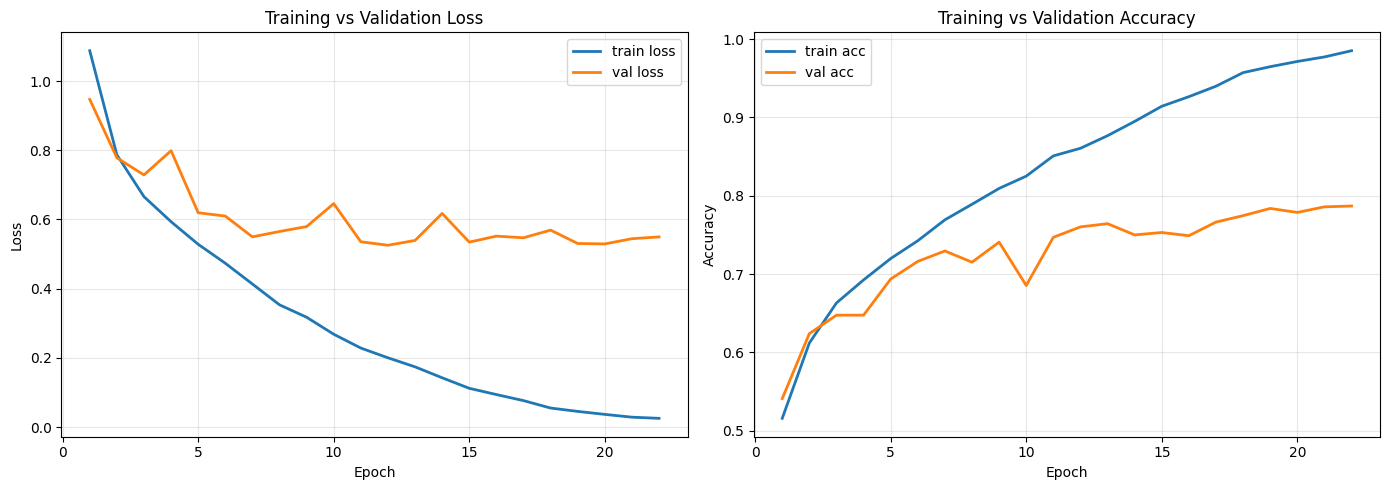

Epochs run: 22
Best val_loss epoch: 12  (val_loss=0.5253)


In [11]:
if experiment_succeeded:
    best_model = search.best_estimator_
    best_estimator = best_model.named_steps['estimator']
    history = best_estimator.get_history_dict()

    loss = history.get('loss', [])
    val_loss = history.get('val_loss', [])
    acc = history.get('accuracy', history.get('predictions_accuracy', []))
    val_acc = history.get('val_accuracy', history.get('val_predictions_accuracy', []))

    has_val = len(val_loss) > 0 and len(val_acc) > 0
    epochs_ran = range(1, len(loss) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    ax = axes[0]
    ax.plot(epochs_ran, loss, label='train loss', linewidth=2)
    if has_val:
        ax.plot(epochs_ran, val_loss, label='val loss', linewidth=2)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.set_title('Training vs Validation Loss')
    ax.grid(alpha=0.3)
    ax.legend()

    ax = axes[1]
    ax.plot(epochs_ran, acc, label='train acc', linewidth=2)
    if has_val:
        ax.plot(epochs_ran, val_acc, label='val acc', linewidth=2)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Accuracy')
    ax.set_title('Training vs Validation Accuracy')
    ax.grid(alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()

    print(f'Epochs run: {len(loss)}')
    if has_val:
        best_epoch = int(np.argmin(val_loss)) + 1
        print(f'Best val_loss epoch: {best_epoch}  (val_loss={min(val_loss):.4f})')


In [12]:
# Each protocol's holdout was evaluated once after its own search/refit
# (both normal holdout and simulated 50%-nullified Thermopile/ToF hidden test).
if experiment_succeeded:
    print('Last validation protocol:', last_run['validation_mode'])
    print('Holdout competition score (normal):', eval_results['competition_score'])
    if 'hidden_test_competition_score' in eval_results:
        print('Holdout competition score (50% Thm/ToF nullified hidden-test):', eval_results['hidden_test_competition_score'])
pd.DataFrame(protocol_results)


Last validation protocol: sequence
Holdout competition score (normal): 0.8053902127192345


,validation_mode,group_column,search_mode,best_cv_score,holdout_score,holdout_competition_score,holdout_binary_f1,holdout_gesture_f1,holdout_macro_f1,holdout_hidden_test_competition_score,holdout_hidden_test_binary_f1,holdout_hidden_test_gesture_f1
0,sequence,None,bayes,0.827904,0.80539,0.80539,0.985075,0.625706,0.660326,NaN,NaN,NaN


In [13]:
print('Experiments CSV:', validation_runs['experiments_path'])
print('Summary JSON:', validation_runs['summary_path'])


Experiments CSV: /kaggle/working/results_multibranch_v3_bfrb_bfrb_bayes/multibranch_v3_bfrb_20261111_013912_experiments.csv
Summary JSON: /kaggle/working/results_multibranch_v3_bfrb_bfrb_bayes/multibranch_v3_bfrb_20261111_013912_summary.json


# Trained-model permutation importance

The score is the decrease in sequence macro-F1 after exchanging whole recording inputs between compatible internal-validation sequences. Motion inputs and their derived representations move together in the coherent motion group; each NOOP feature (including `cr7_kimmitch` features) is additionally permuted in its own column. Donors share the same chunk count and padding layout.


Importance scope: saved internal validation sequences
Internal baseline macro-F1: 0.6705248107353322
Permutable sequence fraction: 0.9475308641975309


,kind,name,importance_mean,importance_std,n_sequences,n_permutable_sequences
0,group,tof,0.314131,0.003393,972,921
1,group,motion_coherent,0.271883,0.010457,972,921
2,group,imu_acceleration,0.220413,0.013520,972,921
3,group,thm,0.089449,0.008218,972,921
4,group,imu_rotation,0.085368,0.011179,972,921
5,noop_feature,noop_cadence_strength,0.025213,0.002883,972,921
6,group,noop_all,0.016022,0.001618,972,921
7,noop_feature,noop_cadence_sublag_hz,0.011952,0.001657,972,921
8,noop_feature,noop_acf_sublag_concavity,0.007982,0.004562,972,921
9,noop_feature,noop_cadence_hz,0.007252,0.004774,972,921


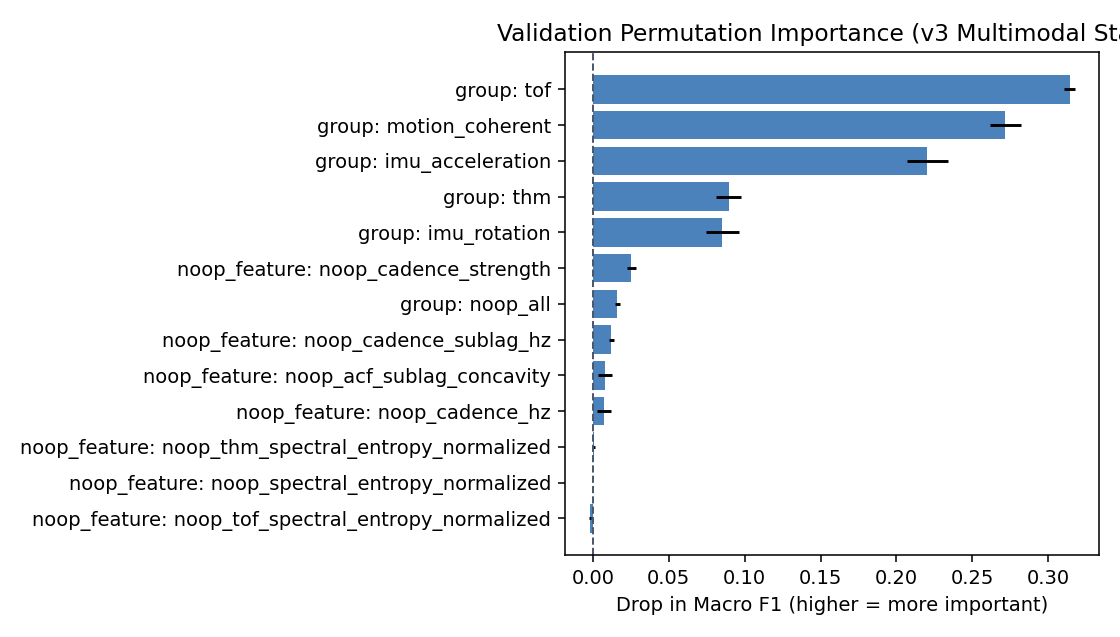

Importance files: {'csv': '/kaggle/working/results_multibranch_v3_bfrb_bfrb_bayes/20261111_013912/multibranch_v3_bfrb_internal_permutation.csv', 'json': '/kaggle/working/results_multibranch_v3_bfrb_bfrb_bayes/20261111_013912/multibranch_v3_bfrb_internal_permutation.json', 'png': '/kaggle/working/results_multibranch_v3_bfrb_bfrb_bayes/20261111_013912/multibranch_v3_bfrb_internal_permutation.png', 'plot': '/kaggle/working/results_multibranch_v3_bfrb_bfrb_bayes/20261111_013912/multibranch_v3_bfrb_internal_permutation.png'}


In [14]:
# Never substitute X_test/y_test here: final holdout is not an importance dataset.
NOOP_IMPORTANCE_REPEATS = 3
noop_importance = None
if experiment_succeeded:
    best_model = search.best_estimator_
    fitted_estimator = best_model.named_steps['estimator']
    internal_ids = pd.Index(getattr(fitted_estimator, 'validation_sequence_ids_', []))
    sequence_col = getattr(fitted_estimator.extractor_, 'sequence_col', 'sequence_id')
    if internal_ids.empty:
        print('Permutation importance skipped: fitted model has no internal validation partition.')
    else:
        raw_internal = X_train.loc[X_train[sequence_col].isin(internal_ids)]
        X_internal = fitted_estimator.extractor_.select_finetuning_sequences(raw_internal, y_train)
        y_internal = y_train.loc[X_internal.index]
        noop_importance = compute_permutation_importance(
            best_model, X_internal, y_internal,
            repeats=NOOP_IMPORTANCE_REPEATS, random_state=random_state,
            include_noop_individual=True, require_internal_validation=True,
            output_dir=results_dir / timestamp,
            prefix=f'{experiment_name}_internal_permutation',
        )
        print('Importance scope:', noop_importance.attrs['scope'])
        print('Internal baseline macro-F1:', noop_importance.attrs['baseline_macro_f1'])
        print('Permutable sequence fraction:', noop_importance.attrs['permutable_fraction'])
        from IPython.display import Image, display
        display(noop_importance[['kind', 'name', 'importance_mean', 'importance_std',
                                 'n_sequences', 'n_permutable_sequences']])
        display(Image(filename=noop_importance.attrs['paths']['plot']))
        print('Importance files:', noop_importance.attrs['paths'])
